# 03 · Feature Engineering for Deep Learning

**What this notebook does.** It decides, with evidence, *which inputs the neural network receives*, builds them without leakage, and writes the files the deep-learning notebooks will read.

**Produces:** `Datasets/processed/dl_train.csv`, `dl_val.csv`, `dl_test.csv` and `feature_spec.json`.

### Ground rules for Phase 2
1. **Every decision carries an argument**, in this order of strength: *mechanism* (theory or the brief) → *evidence* (a paired comparison with its 95% interval) → *parsimony* (when evidence cannot separate two options, the simpler one wins). "Everyone does it" is not an argument.
2. **The shipped model is deep learning only.** Classical ML appears here only as a **measuring instrument** (a gradient-boosting ruler, logistic regression, SVD) to justify feature decisions. None of it sits in the prediction path.
3. **Nov–Dec is never used to make a decision.** All evidence comes from Jan–Oct using rolling-origin folds. The test months are only transformed and saved at the end.

### How to read a decision
**Decision box** (rule and reason) → code that produces the evidence → **Verdict**.

### Result in brief (from the run below)

| | Phase 1 | Phase 2 network input |
|---|---|---|
| Columns the model sees | 2,071 (1,948 of them one-hot flight numbers) | **9**: 3 categorical (carrier, origin, destination → embeddings) + 6 numeric |
| Departure time | hour sin/cos + raw minute-of-hour | one sin/cos pair at **minute** resolution |
| Evidence standard | one validation split, one number | 5 rolling-origin folds, paired day-block bootstrap, 95% intervals |

* **Recommended groups:** weekday, carrier, origin, destination, distance, congestion, time of day (minute resolution). Against the core set: **+0.0028 AP** (95% interval +0.0014 to +0.0041).
* **Not recommended:** arrival hour, season, route, flight number (no measurable gain), raw minute-of-hour (superseded by minute-resolution time of day) and past-delay rates (**hurt**: −0.043 AP, and still no setting of their own rescues them: Decision 4b).
* **Saved once, read everywhere:** `Datasets/processed/` holds the model-ready splits, a readable featured table with a split label and `feature_spec.json` (the contract; it also rebuilds the encoder). Notebook 04 and the DL notebooks open them with `DatasetStore`.
* **Deliberately not decided here:** architecture, embedding sizes, loss, activation, initialisation, optimiser, early-stopping metric, calibration method. Each gets its own decision box in the DL notebooks.

### How to run
1. Put this notebook in `Notebooks/` of the repo, next to `Datasets/flights.zip`. There is nothing else to copy: the code is in Part A.
2. Needs pandas, numpy, scikit-learn and matplotlib. Run all cells top to bottom (about 5 minutes on one CPU; set `QUICK = True` for a short dry run).
3. The notebook writes `Datasets/processed/` (about 15 MB compressed). **Commit it**, so notebook 04, your teammates and a fresh Colab session start from the same files. Colab's disk is wiped when the session ends.
4. Library versions can move numbers in the last digit shown (checked on pandas 3.0 and pandas 2.2: every verdict and the recommended set were identical).

## Architecture (system design)

One notebook, two parts. **Part A** is the code, in seven small layers, one cell each. **Part B** is the decisions and the evidence, and only *uses* those layers. Why classes inside a notebook at all? So that one decision can change one thing without touching the others, and so the leakage guard cannot be bypassed by accident.

```text
Datasets/flights.zip
      │  load_flights ................... reads + labels, nothing else
      ▼
FeaturePipeline ◄─ leakage guard ......... every block declares what it reads; leakage = error
  ├─ PassThroughBlock   carrier, origin, dest, distance
  ├─ CalendarBlock      hour and weekday as sin/cos
  ├─ CongestionBlock    scheduled flights per origin-hour
  └─ candidate extras   arrival hour · season · minute-of-hour · fine time · route · flight id · past delay
      │
ChronologicalSplit / rolling_origin_folds ... month-based, never shuffled
      │
DLEncoder.fit(train only) ................ category ids (+ <UNK>) and z-scored numbers
      │
DatasetStore.save ........................ Datasets/processed/: model-ready splits, readable table, feature_spec.json
      │
      ▼   read by notebook 04 (baselines, tuning, cost) and by the DL notebooks
```

| Principle | Where it shows up |
|---|---|
| **S**ingle responsibility | `load_flights` reads · blocks build · `ChronologicalSplit` splits · `DLEncoder` encodes · `DatasetStore` does file I/O · the evidence tools measure |
| **O**pen/closed | a new feature = a new `FeatureBlock` subclass; the pipeline is not edited (a live example is in Decision 1) |
| **L**iskov | every block returns the same index and exactly its declared columns, so blocks are interchangeable |
| **I**nterface segregation | a block exposes only `transform`, `produces`, `reads`; a splitter only `split` |
| **D**ependency inversion | the pipeline depends on the `FeatureBlock` abstraction and an injected `Config`, never on concrete blocks or globals |

Notebook 04 does not import this notebook. It reads the saved files and re-defines only the small reader and metrics it needs.

## Part A · The code

Seven layers, each in its own cell. Read them once; Part B only uses them. Every layer has one reason to change.

In [1]:
import sys, json, time, warnings
from abc import ABC, abstractmethod
from dataclasses import dataclass, replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
warnings.filterwarnings("ignore")

### A1 · config

Single source of truth for every decision that is a name or a number. When someone asks "why 15 minutes?" or "which months are test?", the answer lives in exactly one place.

In [2]:
# ----------------------------------------------------------------------------------------
# 1. Column policy: every raw column, what we may do with it, and why.
#    (Decision 1: the network predicts at 18:00 on the day before departure.)
# ----------------------------------------------------------------------------------------
ALLOWED = "allowed"                  # part of the published schedule: known at prediction time
POST_DEPARTURE = "post_departure"    # exists only after the plane moves -> leakage
TARGET = "target"                    # defines the label
UNRELIABLE = "unreliable"            # may change after the prediction time
REDUNDANT = "redundant"              # duplicates another column or carries nothing

COLUMN_POLICY = {
    "id":             (REDUNDANT,      "row counter, carries no information"),
    "year":           (ALLOWED,        "calendar date of the scheduled departure"),
    "month":          (ALLOWED,        "calendar date of the scheduled departure"),
    "day":            (ALLOWED,        "calendar date of the scheduled departure"),
    "date":           (ALLOWED,        "built from year/month/day"),
    "sched_dep_time": (ALLOWED,        "published schedule"),
    "sched_arr_time": (ALLOWED,        "published schedule"),
    "carrier":        (ALLOWED,        "published schedule"),
    "flight":         (ALLOWED,        "published, but an identifier rather than a cause (tested as an extra)"),
    "origin":         (ALLOWED,        "published schedule"),
    "dest":           (ALLOWED,        "published schedule"),
    "distance":       (ALLOWED,        "fixed property of the route"),
    "hour":           (ALLOWED,        "restates the scheduled departure hour"),
    "minute":         (ALLOWED,        "restates the scheduled departure minute"),
    "time_hour":      (ALLOWED,        "restates the scheduled departure hour"),
    "name":           (REDUNDANT,      "airline name, duplicates carrier"),
    "tailnum":        (UNRELIABLE,     "aircraft assignment can change after 18:00 the day before; has missing values"),
    "dep_time":       (POST_DEPARTURE, "actual departure time"),
    "dep_delay":      (POST_DEPARTURE, "actual minus scheduled departure: the strongest predictor, pure leakage at 18:00"),
    "arr_time":       (POST_DEPARTURE, "actual arrival time"),
    "air_time":       (POST_DEPARTURE, "actual time in the air"),
    "arr_delay":      (TARGET,         "defines the label; only OLD days' values may be used, lagged by >= 2 days"),
}
FORBIDDEN_STATUSES = {POST_DEPARTURE, TARGET, UNRELIABLE}

# ----------------------------------------------------------------------------------------
# 2. Feature catalogue. CORE groups are kept by mechanism (and by the brief);
#    EXTRA groups are candidates that must earn their place with evidence (Decision 4).
# ----------------------------------------------------------------------------------------
CORE_GROUPS = {
    "hour":        ["hour_sin", "hour_cos"],
    "weekday":     ["weekday_sin", "weekday_cos"],
    "carrier":     ["carrier"],
    "origin":      ["origin"],
    "destination": ["dest"],
    "distance":    ["distance"],
    "congestion":  ["scheduled_origin_hour_count"],
}
EXTRA_GROUPS = {
    "arrival_hour":   ["arr_hour_sin", "arr_hour_cos"],
    "season":         ["year_day_sin", "year_day_cos"],
    "minute_of_hour": ["sched_minute", "sched_arr_minute"],
    "fine_time":      ["tod_sin", "tod_cos"],
    "route":          ["route"],
    "flight_id":      ["flight_top"],
    "past_delay":     ["origin_delay_7d", "carrier_delay_7d", "nyc_delay_7d"],
}
CATEGORICAL_COLUMNS = {"carrier", "origin", "dest", "route", "flight_top"}

GROUP_WHY = {
    "hour":           "delays build up through the day; sin/cos makes 23:00 and 00:00 neighbours",
    "weekday":        "weekly travel pattern; cyclic like hour",
    "carrier":        "airlines differ in operations; the brief asks for an airline embedding",
    "origin":         "airport-specific conditions; the brief asks for an origin embedding",
    "destination":    "route effects; the brief asks for a destination embedding",
    "distance":       "route length: more exposure to en-route weather, more room to absorb delay",
    "congestion":     "scheduled departures from the same airport in the same hour (runway pressure)",
    "arrival_hour":   "does arrival-time pressure add anything beyond departure hour?",
    "season":         "smooth day-of-year curve; risky because the test season is never seen in training",
    "minute_of_hour": "Phase 1's sched_minute / sched_arr_minute (minute inside the hour, 0-59)",
    "fine_time":      "departure time of day at minute resolution as one sin/cos pair (hour-only drops the minute)",
    "route":          "origin-destination pair as one category",
    "flight_id":      "flight number (top 250 + OTHER): an identifier, not a cause",
    "past_delay":     "delay rate of the last 7 complete days (origin, carrier, whole network), lagged 2 days",
}


# ----------------------------------------------------------------------------------------
# 3. Numbers.
# ----------------------------------------------------------------------------------------
@dataclass(frozen=True)
class Config:
    # where things live (relative to the repo root)
    raw_zip: str = "Datasets/flights.zip"
    out_dir: str = "Datasets/processed"

    # the label: "delayed" = arrives >= 15 minutes late (the BTS definition)
    delay_minutes: int = 15

    # prediction time (the rule the guard enforces)
    prediction_time: str = "18:00 on the day before the scheduled departure"
    min_outcome_lag_days: int = 2        # a day's outcomes are complete only after that day has ended

    # splits, as calendar months of 2013
    train_months: tuple = (1, 2, 3, 4, 5, 6, 7, 8)
    val_months: tuple = (9, 10)
    test_months: tuple = (11, 12)
    fold_val_months: tuple = (6, 7, 8, 9, 10)    # rolling origin: train on every earlier month

    # feature settings
    top_k_flights: int = 250
    flight_reference_months: tuple = (1, 2, 3, 4, 5)   # months available to every fold
    past_window_days: int = 7
    past_lag_days: int = 2
    past_prior: float = 0.25             # declared constant, not learned from labels
    past_strength: float = 30.0          # pseudo-flights given to the prior
    min_category_count: int = 100        # categories rarer than this in train share one <UNK> token

    # evidence tools
    n_bootstrap: int = 200
    seed: int = 42

### A2 · data

Read the raw file and attach the label. Nothing else lives here.

In [3]:
def load_flights(cfg: Config, root) -> pd.DataFrame:
    """One row per scheduled flight, sorted by time, with `date`, `labelled` and `y` added.

    Cancelled/diverted flights have no arrival delay: they stay in the table (they were on the
    published schedule) but have labelled=False and y=NaN.
    """
    df = pd.read_csv(Path(root) / cfg.raw_zip)

    missing = (set(COLUMN_POLICY) - {"date"}) - set(df.columns)
    if missing:
        raise ValueError(f"raw file is missing columns: {sorted(missing)}")

    df["date"] = pd.to_datetime(df[["year", "month", "day"]])
    df["labelled"] = df["arr_delay"].notna()
    df["y"] = np.where(df["labelled"], (df["arr_delay"] >= cfg.delay_minutes).astype(float), np.nan)
    return df.sort_values(["date", "sched_dep_time", "id"]).reset_index(drop=True)

### A3 · splits

Split rows by calendar month. Never shuffles: delays cluster by day and by season.

In [4]:
class ChronologicalSplit:
    """train / val / test by month, in time order."""

    def __init__(self, cfg: Config):
        self.cfg = cfg

    def assign(self, df: pd.DataFrame) -> pd.Series:
        """The split name of every row: 'train', 'val', 'test' (or 'unassigned' if its month is in none of them)."""
        month = df["month"]
        names = np.select([month.isin(self.cfg.train_months), month.isin(self.cfg.val_months),
                           month.isin(self.cfg.test_months)], ["train", "val", "test"], default="unassigned")
        return pd.Series(names, index=df.index, name="split")

    def split(self, df: pd.DataFrame) -> dict:
        labels = self.assign(df)
        parts = {name: df[labels == name] for name in ("train", "val", "test")}
        self.check(parts)
        return parts

    @staticmethod
    def check(parts: dict) -> None:
        assert parts["train"]["date"].max() < parts["val"]["date"].min(), "train must end before val starts"
        assert parts["val"]["date"].max() < parts["test"]["date"].min(), "val must end before test starts"


def rolling_origin_folds(months: np.ndarray, validation_months) -> list:
    """[(train_mask, val_mask), ...]: for each month m, train on every EARLIER month, validate on m."""
    months = np.asarray(months)
    return [(months < m, months == m) for m in validation_months]

### A4 · features

One block = one family of features = one reason to change. Every block returns the same index and exactly its declared columns, and a guard refuses any block that reads something unknown at prediction time.

In [5]:
class LeakageError(Exception):
    """A block tried to read something that is not known at prediction time."""


class FeatureBlock(ABC):
    name: str = ""
    produces: tuple = ()                 # columns this block creates
    reads: frozenset = frozenset()       # raw columns it looks at (checked by the guard)
    outcome_lag_days = None              # set ONLY by blocks that read past outcomes

    @abstractmethod
    def transform(self, df: pd.DataFrame) -> pd.DataFrame:
        ...


def _cyclic(values, period, prefix) -> dict:
    """sin/cos pair, so the end of the cycle is next to its start (23:00 ~ 00:00, Sunday ~ Monday)."""
    angle = 2 * np.pi * values / period
    return {f"{prefix}_sin": np.sin(angle), f"{prefix}_cos": np.cos(angle)}


# ---------------------------------------------------------------- core blocks
class PassThroughBlock(FeatureBlock):
    """Published schedule columns used as they are."""
    name = "schedule"

    def __init__(self, columns):
        self.produces = tuple(columns)
        self.reads = frozenset(columns)

    def transform(self, df):
        return df[list(self.produces)].copy()


class CalendarBlock(FeatureBlock):
    name = "calendar"
    produces = ("hour_sin", "hour_cos", "weekday_sin", "weekday_cos")
    reads = frozenset({"sched_dep_time", "date"})

    def transform(self, df):
        hour = df["sched_dep_time"] // 100
        weekday = df["date"].dt.dayofweek
        return pd.DataFrame({**_cyclic(hour, 24, "hour"), **_cyclic(weekday, 7, "weekday")}, index=df.index)


class CongestionBlock(FeatureBlock):
    """Flights scheduled from the same airport in the same hour on the same day.

    Must run on the FULL schedule (cancelled flights included): at 18:00 the day before, a flight
    that will later be cancelled is still on the schedule (Decision 2).
    """
    name = "congestion"
    produces = ("scheduled_origin_hour_count",)
    reads = frozenset({"date", "origin", "sched_dep_time"})

    def transform(self, df):
        hour = df["sched_dep_time"] // 100
        count = df.groupby([df["date"], df["origin"], hour])["origin"].transform("size")
        return pd.DataFrame({"scheduled_origin_hour_count": count}, index=df.index)


# ---------------------------------------------------------------- extra blocks (candidates)
class ArrivalHourBlock(FeatureBlock):
    name = "arrival_hour"
    produces = ("arr_hour_sin", "arr_hour_cos")
    reads = frozenset({"sched_arr_time"})

    def transform(self, df):
        return pd.DataFrame(_cyclic(df["sched_arr_time"] // 100, 24, "arr_hour"), index=df.index)


class SeasonBlock(FeatureBlock):
    name = "season"
    produces = ("year_day_sin", "year_day_cos")
    reads = frozenset({"date"})

    def transform(self, df):
        return pd.DataFrame(_cyclic(df["date"].dt.dayofyear - 1, 365.25, "year_day"), index=df.index)


class MinuteOfHourBlock(FeatureBlock):
    """Phase 1's sched_minute / sched_arr_minute: the minute INSIDE the hour (0-59)."""
    name = "minute_of_hour"
    produces = ("sched_minute", "sched_arr_minute")
    reads = frozenset({"sched_dep_time", "sched_arr_time"})

    def transform(self, df):
        return pd.DataFrame({"sched_minute": df["sched_dep_time"] % 100,
                             "sched_arr_minute": df["sched_arr_time"] % 100}, index=df.index)


class FineTimeBlock(FeatureBlock):
    """Departure time of day at MINUTE resolution as one sin/cos pair (hour-only encoding throws the minute away)."""
    name = "fine_time"
    produces = ("tod_sin", "tod_cos")
    reads = frozenset({"sched_dep_time"})

    def transform(self, df):
        time_of_day = df["sched_dep_time"] // 100 + (df["sched_dep_time"] % 100) / 60
        return pd.DataFrame(_cyclic(time_of_day, 24, "tod"), index=df.index)


class RouteBlock(FeatureBlock):
    name = "route"
    produces = ("route",)
    reads = frozenset({"origin", "dest"})

    def transform(self, df):
        return pd.DataFrame({"route": df["origin"] + "-" + df["dest"]}, index=df.index)


class FlightIdBlock(FeatureBlock):
    """Flight number, keeping the `top_k` most frequent in the reference months and 'OTHER' for the rest."""
    name = "flight_id"
    produces = ("flight_top",)
    reads = frozenset({"flight", "month"})

    def __init__(self, cfg: Config):
        self.top_k = cfg.top_k_flights
        self.reference_months = cfg.flight_reference_months

    def transform(self, df):
        reference = df.loc[df["month"].isin(self.reference_months), "flight"]
        top = reference.value_counts().head(self.top_k).index
        label = df["flight"].astype(str)
        return pd.DataFrame({"flight_top": label.where(df["flight"].isin(top), "OTHER")}, index=df.index)


class PastDelayBlock(FeatureBlock):
    """Share of delayed flights over the last `window` COMPLETE days, ending `lag` days before the flight.

    The only block allowed to touch outcomes. It declares `outcome_lag_days`, and the guard refuses
    any lag below 2 days: at 18:00 the day before, yesterday's outcomes are still incomplete.
    Rates are smoothed towards a declared prior so that quiet keys do not produce 0% or 100%.
    """
    name = "past_delay"
    reads = frozenset({"date", "origin", "carrier"})

    def __init__(self, cfg: Config):
        self.window, self.lag = cfg.past_window_days, cfg.past_lag_days
        self.prior, self.strength = cfg.past_prior, cfg.past_strength
        self.outcome_lag_days = cfg.past_lag_days
        w = cfg.past_window_days
        self.produces = (f"origin_delay_{w}d", f"carrier_delay_{w}d", f"nyc_delay_{w}d")

    def _rates(self, df: pd.DataFrame, key) -> pd.DataFrame:
        days = pd.date_range(df["date"].min(), df["date"].max())
        labelled = df[df["y"].notna()]
        groups = labelled.groupby(key) if key else [("all", labelled)]
        pieces = []
        for value, g in groups:
            daily = g.groupby("date")["y"].agg(delayed="sum", flights="count").reindex(days, fill_value=0)
            past = daily.rolling(self.window, min_periods=1).sum().shift(self.lag)   # days D-lag-window+1 .. D-lag
            rate = (past["delayed"] + self.strength * self.prior) / (past["flights"] + self.strength)
            pieces.append(pd.DataFrame({"date": days, "key": value, "rate": rate.fillna(self.prior).to_numpy()}))
        return pd.concat(pieces, ignore_index=True)

    def transform(self, df):
        out = {}
        for column, key in zip(self.produces, ["origin", "carrier", None]):
            rates = self._rates(df, key)
            if key:
                lookup = df[["date", key]].merge(rates, left_on=["date", key], right_on=["date", "key"], how="left")
            else:
                lookup = df[["date"]].merge(rates[["date", "rate"]], on="date", how="left")
            out[column] = lookup["rate"].to_numpy()
        return pd.DataFrame(out, index=df.index)


# ---------------------------------------------------------------- pipeline
class FeaturePipeline:
    """Composes blocks. Knows only the FeatureBlock contract, never a concrete block (Dependency Inversion)."""

    def __init__(self, blocks, cfg: Config):
        self.blocks, self.cfg = list(blocks), cfg
        for block in self.blocks:
            self._guard(block)

    def _guard(self, block: FeatureBlock) -> None:
        """Decision 1, enforced in code instead of by good intentions."""
        for column in block.reads:
            status = COLUMN_POLICY.get(column, ("allowed", ""))[0]
            if status in FORBIDDEN_STATUSES:
                raise LeakageError(f"block '{block.name}' reads '{column}' ({status}): not known at "
                                   f"{self.cfg.prediction_time}")
        lag = block.outcome_lag_days
        if lag is not None and lag < self.cfg.min_outcome_lag_days:
            raise LeakageError(f"block '{block.name}' reads outcomes lagged {lag} day(s); "
                               f"at least {self.cfg.min_outcome_lag_days} are needed")

    def transform(self, df: pd.DataFrame) -> pd.DataFrame:
        parts = []
        for block in self.blocks:
            part = block.transform(df)
            if tuple(part.columns) != tuple(block.produces) or not part.index.equals(df.index):
                raise ValueError(f"block '{block.name}' broke the contract (columns or index differ)")
            parts.append(part)
        return pd.concat(parts, axis=1)

    def describe(self) -> pd.DataFrame:
        return pd.DataFrame([{"block": b.name, "produces": ", ".join(b.produces),
                              "reads (raw)": ", ".join(sorted(b.reads)),
                              "reads past outcomes": b.outcome_lag_days is not None} for b in self.blocks])


def default_blocks(cfg: Config) -> list:
    """Every candidate block. Which extras reach the network is decided by evidence in the notebook."""
    return [PassThroughBlock(["carrier", "origin", "dest", "distance"]), CalendarBlock(), CongestionBlock(),
            ArrivalHourBlock(), SeasonBlock(), MinuteOfHourBlock(), FineTimeBlock(), RouteBlock(),
            FlightIdBlock(cfg), PastDelayBlock(cfg)]

### A5 · encoding

Turn engineered columns into what a neural network consumes. Fitted on **train rows only**; index 0 is reserved for `<UNK>`.

In [6]:
UNKNOWN = "<UNK>"


class DLEncoder:
    """Categories -> integer ids (for embedding layers). Numbers -> z-scores (train mean and std).

    Index 0 is reserved for <UNK>: categories rarer than `min_count` in train, or never seen in train.
    """

    def __init__(self, categorical, numeric, min_count: int):
        self.categorical, self.numeric, self.min_count = list(categorical), list(numeric), min_count

    def fit(self, train: pd.DataFrame) -> "DLEncoder":
        self.vocab_ = {}
        for col in self.categorical:
            counts = train[col].astype(str).value_counts()
            self.vocab_[col] = [UNKNOWN] + counts[counts >= self.min_count].index.tolist()
        self.mean_ = train[self.numeric].mean().to_dict()
        self.std_ = train[self.numeric].std().replace(0, 1.0).to_dict()
        return self

    def transform(self, df: pd.DataFrame) -> pd.DataFrame:
        out = pd.DataFrame(index=df.index)
        for col in self.categorical:
            ids = {token: i for i, token in enumerate(self.vocab_[col])}
            out[f"{col}_idx"] = df[col].astype(str).map(ids).fillna(0).astype("int64")
        for col in self.numeric:
            out[col] = (df[col] - self.mean_[col]) / self.std_[col]
        return out

    def coverage(self, df: pd.DataFrame) -> dict:
        """Share of rows that fall into <UNK>, per categorical column."""
        encoded = self.transform(df)
        return {col: float((encoded[f"{col}_idx"] == 0).mean()) for col in self.categorical}

    def spec(self) -> dict:
        return {
            "categorical": {c: {"vocab_size": len(v), "tokens": v} for c, v in self.vocab_.items()},
            "numeric": {c: {"mean": self.mean_[c], "std": self.std_[c]} for c in self.numeric},
            "min_count": self.min_count,
        }

    @classmethod
    def load(cls, path) -> "DLEncoder":
        """Rebuild a fitted encoder from feature_spec.json (no training data needed)."""
        with open(path) as f:
            spec = json.load(f)
        encoder = cls(list(spec["categorical"]), list(spec["numeric"]), spec["min_count"])
        encoder.vocab_ = {c: v["tokens"] for c, v in spec["categorical"].items()}
        encoder.mean_ = {c: v["mean"] for c, v in spec["numeric"].items()}
        encoder.std_ = {c: v["std"] for c, v in spec["numeric"].items()}
        return encoder

    def save(self, path, extra: dict) -> None:
        with open(path, "w") as f:
            json.dump({**self.spec(), **extra}, f, indent=2)

### A6 · store

Save the featured dataset once; every later notebook only reads it. One saved copy means every model sees identical rows and identical splits.

In [7]:
SPLITS = ("train", "val", "test")


class DatasetStore:
    """One folder:

        dl_<split>.csv.gz    model-ready inputs: category ids + z-scored numbers, plus row_id, y, month, date
        features_all.csv.gz  the same flights as readable engineered features, with a `split` label
        feature_spec.json    the contract: vocabularies, means/stds, groups, splits, file manifest
    """

    def __init__(self, folder):
        self.folder = Path(folder)

    # ------------------------------------------------------------------ writing (feature notebook only)
    def save(self, readable: pd.DataFrame, model_ready: dict, encoder: DLEncoder, extra: dict) -> dict:
        self.folder.mkdir(parents=True, exist_ok=True)
        tables = {**{f"dl_{name}": model_ready[name] for name in SPLITS}, "features_all": readable}
        files = {}
        for name, frame in tables.items():
            path = self.folder / f"{name}.csv.gz"
            frame.to_csv(path, index=False, float_format="%.6g")
            files[path.name] = {"rows": len(frame), "columns": list(frame.columns),
                                "size_mb": round(path.stat().st_size / 1e6, 1)}
        encoder.save(self.folder / "feature_spec.json", extra={**extra, "files": files})
        return files

    # ------------------------------------------------------------------ reading (every later notebook)
    def spec(self) -> dict:
        with open(self.folder / "feature_spec.json") as f:
            return json.load(f)

    def load_encoder(self) -> DLEncoder:
        return DLEncoder.load(self.folder / "feature_spec.json")

    def load_split(self, name: str, groups=None):
        """(X, y, meta) for 'train', 'val' or 'test'. X holds the columns of `groups` (default: the recommended ones)."""
        spec = self.spec()
        columns = [c for g in (groups or spec["recommended_groups"]) for c in spec["groups"][g]]
        frame = pd.read_csv(self.folder / f"dl_{name}.csv.gz", parse_dates=["date"])
        meta = frame[[c for c in spec["meta_columns"] if c != "y"]]
        return frame[columns], frame["y"].astype(int), meta

    def load_development(self, groups=None):
        """Train + val stacked (Jan-Oct): the data for rolling-origin folds. Test is never included."""
        parts = [self.load_split(name, groups) for name in ("train", "val")]
        return tuple(pd.concat(part, ignore_index=True) for part in zip(*parts))

    def load_readable(self) -> pd.DataFrame:
        return pd.read_csv(self.folder / "features_all.csv.gz", parse_dates=["date"])

### A7 · evidence tools

Measuring instruments used to justify decisions. **None of this is part of the final model.** The gradient-boosting "proxy" is a ruler: a fast non-linear model that tells us whether a feature group carries signal.

In [8]:
# ---------------------------------------------------------------- the proxy ruler
def to_matrix(features: pd.DataFrame, columns, categorical) -> np.ndarray:
    """Numeric matrix for the proxy: categories become integer codes, numbers stay numbers."""
    cols = []
    for c in columns:
        if c in categorical:
            cols.append(pd.Categorical(features[c]).codes.astype("float64"))
        else:
            cols.append(features[c].to_numpy(dtype="float64"))
    return np.column_stack(cols)


def proxy_model(columns, categorical, seed: int) -> HistGradientBoostingClassifier:
    mask = [c in categorical for c in columns]
    return HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, max_depth=5, min_samples_leaf=100,
                                          categorical_features=mask if any(mask) else None, random_state=seed)


def fit_and_score(features, y, train_mask, val_mask, columns, categorical, seed) -> dict:
    X = to_matrix(features, columns, categorical)
    model = proxy_model(columns, categorical, seed).fit(X[train_mask], y[train_mask])
    p = model.predict_proba(X[val_mask])[:, 1]
    return {"AUC": roc_auc_score(y[val_mask], p), "AP": average_precision_score(y[val_mask], p)}


def out_of_fold(features, y, months, columns, categorical, validation_months, seed) -> np.ndarray:
    """Rolling-origin predictions: NaN for rows that are never validated."""
    X = to_matrix(features, columns, categorical)
    pred = np.full(len(y), np.nan)
    for train, val in rolling_origin_folds(months, validation_months):
        model = proxy_model(columns, categorical, seed).fit(X[train], y[train])
        pred[val] = model.predict_proba(X[val])[:, 1]
    return pred


# ---------------------------------------------------------------- uncertainty: paired day-block bootstrap
def weighted_average_precision(y, p, weight=None):
    return average_precision_score(y, p, sample_weight=weight)


def day_bootstrap(y, predictions: dict, days, n_boot: int, seed: int, metric=weighted_average_precision):
    """A metric (default: average precision) of every prediction vector on the SAME resampled days (paired).

    Flights on one day share weather and congestion, so we resample whole DAYS, not rows.
    Returns (point estimates, {name: array of n_boot resampled scores}).
    """
    keep = np.all([~np.isnan(p) for p in predictions.values()], axis=0)
    y, days = np.asarray(y)[keep], np.asarray(days)[keep]
    preds = {name: np.asarray(p)[keep] for name, p in predictions.items()}
    day_id, n_days = pd.factorize(days)[0], len(pd.unique(days))
    rng = np.random.default_rng(seed)
    draws = {name: np.empty(n_boot) for name in preds}
    for b in range(n_boot):
        weight = np.bincount(rng.integers(0, n_days, n_days), minlength=n_days)[day_id]
        used = weight > 0
        for name, p in preds.items():
            draws[name][b] = metric(y[used], p[used], weight[used])
    point = {name: metric(y, p, None) for name, p in preds.items()}
    return point, draws


def compare_to_baseline(point: dict, draws: dict, baseline: str) -> pd.DataFrame:
    """Each variant against the baseline: difference in AP and its 95% interval."""
    rows = []
    for name, d in draws.items():
        lo, hi = np.percentile(d - draws[baseline], [2.5, 97.5])
        rows.append({"variant": name, "AP": point[name], "delta_AP": point[name] - point[baseline],
                     "ci_low": lo, "ci_high": hi})
    return pd.DataFrame(rows)


def apply_rule(kind: str, lo: float, hi: float) -> str:
    """The written decision rule, applied identically to every candidate.

    addition: an EXTRA must show a gain whose interval is entirely above zero.
    removal : a CORE group is kept by mechanism; this only reports how much it matters.
    """
    if kind == "addition":
        if lo > 0:
            return "ADMIT (interval above zero)"
        if hi < 0:
            return "REJECT (hurts)"
        return "REJECT (no measurable gain)"
    if hi < 0:
        return "KEEP (removing it hurts)"
    if lo > 0:
        return "REVIEW (removing it helps)"
    return "KEEP by mechanism (effect not measurable here)"


# ---------------------------------------------------------------- calibration
def ece(y, p, bins: int = 10) -> float:
    """Expected calibration error: average gap between predicted and observed rate, over probability bins."""
    y, p = np.asarray(y), np.asarray(p)
    which = np.digitize(p, np.linspace(0, 1, bins + 1)[1:-1])
    return float(sum((which == b).mean() * abs(y[which == b].mean() - p[which == b].mean())
                     for b in range(bins) if (which == b).any()))


def calibration_summary(y, p) -> dict:
    return {"AP": average_precision_score(y, p), "ROC_AUC": roc_auc_score(y, p),
            "mean_predicted": float(np.mean(p)), "observed_rate": float(np.mean(y)),
            "Brier": brier_score_loss(y, p), "ECE": ece(y, p)}

## Part B · Decisions and evidence

Each decision is a box: rule, reason, evidence, verdict, and what would change our mind.

In [9]:
# Find the repo root (the folder containing Datasets/flights.zip).
here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p / "Datasets" / "flights.zip").exists()), None)
assert ROOT is not None, "Run this notebook inside the repo (Datasets/flights.zip not found)."

CFG = Config()
QUICK = False        # True = 3 folds and 100 bootstrap draws (about a third of the run time)
if QUICK:
    CFG = replace(CFG, fold_val_months=(8, 9, 10), n_bootstrap=100)
np.random.seed(CFG.seed)
plt.rcParams.update({"figure.figsize": (7, 3.2), "axes.grid": True, "grid.alpha": 0.3})
print("repo root:", ROOT)

repo root: /Users/aarsh.user/Desktop/AML_DLProject


In [10]:
flights = load_flights(CFG, ROOT)
n_lab = int(flights["labelled"].sum())
print(f"{len(flights):,} scheduled flights | {n_lab:,} labelled | {len(flights) - n_lab:,} cancelled/diverted (no arrival delay)")
print(f"delayed = arrives >= {CFG.delay_minutes} min late: {flights['y'].mean():.1%} of labelled flights")

336,776 scheduled flights | 327,346 labelled | 9,430 cancelled/diverted (no arrival delay)
delayed = arrives >= 15 min late: 24.5% of labelled flights


## Decision 1 · The network predicts at 18:00 the day before, and sees only what is published by then

| | |
|---|---|
| **Rule** | A feature may be used only if it is known at **18:00 on the day before the scheduled departure**. |
| **Why this time** | (1) A day-ahead prediction is the one an airline could still act on, which is what the rescheduling analysis in the brief needs. (2) It is the Phase 1 protocol, so Phase 2 stays comparable. (3) The brief says to fix the prediction timestamp *first*. |
| **What it rules out** | Actual departure and arrival fields, weather observations, and how earlier flights *on the same day* performed. |
| **Evidence** | the policy table → the guard refusing leaky code → what leakage would have looked like |
| **We change our mind if** | the team deliberately adds a *second*, later decision time (e.g. 2 h before departure) with its own policy table. |

In [11]:
# Every raw column, what we may do with it, and why. The guard below enforces this table.
policy = pd.DataFrame([(c, s, why) for c, (s, why) in COLUMN_POLICY.items()], columns=["column", "status", "reason"])
policy.sort_values(["status", "column"]).reset_index(drop=True)

,column,status,reason
0,carrier,allowed,published schedule
1,date,allowed,built from year/month/day
2,day,allowed,calendar date of the scheduled departure
3,dest,allowed,published schedule
4,distance,allowed,fixed property of the route
5,flight,allowed,"published, but an identifier rather than a cau..."
6,hour,allowed,restates the scheduled departure hour
7,minute,allowed,restates the scheduled departure minute
8,month,allowed,calendar date of the scheduled departure
9,origin,allowed,published schedule


In [12]:
pipeline = FeaturePipeline(default_blocks(CFG), CFG)     # the leakage guard runs here, when the pipeline is built
pipeline.describe()

,block,produces,reads (raw),reads past outcomes
0,schedule,"carrier, origin, dest, distance","carrier, dest, distance, origin",False
1,calendar,"hour_sin, hour_cos, weekday_sin, weekday_cos","date, sched_dep_time",False
2,congestion,scheduled_origin_hour_count,"date, origin, sched_dep_time",False
3,arrival_hour,"arr_hour_sin, arr_hour_cos",sched_arr_time,False
4,season,"year_day_sin, year_day_cos",date,False
5,minute_of_hour,"sched_minute, sched_arr_minute","sched_arr_time, sched_dep_time",False
6,fine_time,"tod_sin, tod_cos",sched_dep_time,False
7,route,route,"dest, origin",False
8,flight_id,flight_top,"flight, month",False
9,past_delay,"origin_delay_7d, carrier_delay_7d, nyc_delay_7d","carrier, date, origin",True


In [13]:
# The guard must REFUSE leakage, not merely discourage it. Two deliberate mistakes:
class DepartureDelayBlock(FeatureBlock):
    """A deliberately WRONG block: it reads the actual departure delay."""
    name = "bad_dep_delay"
    produces = ("dep_delay",)
    reads = frozenset({"dep_delay"})
    def transform(self, df):
        return df[["dep_delay"]]

one_day = replace(CFG, past_lag_days=1)
attempts = {
    "a block that reads dep_delay": lambda: FeaturePipeline(default_blocks(CFG) + [DepartureDelayBlock()], CFG),
    "past-delay block lagged 1 day": lambda: FeaturePipeline([PastDelayBlock(one_day)], one_day),
}
for label, build in attempts.items():
    try:
        build()
        print(f"NOT BLOCKED: {label}")
    except LeakageError as err:
        print(f"blocked | {label}\n        -> {err}")

blocked | a block that reads dep_delay
        -> block 'bad_dep_delay' reads 'dep_delay' (post_departure): not known at 18:00 on the day before the scheduled departure
blocked | past-delay block lagged 1 day
        -> block 'past_delay' reads outcomes lagged 1 day(s); at least 2 are needed


In [14]:
features = pipeline.transform(flights)        # every candidate feature, for every scheduled flight
print(features.shape, "| NaNs:", int(features.isna().sum().sum()))
features.head(3).T

(336776, 22) | NaNs: 0


,0,1,2
carrier,UA,UA,AA
origin,EWR,LGA,JFK
dest,IAH,IAH,MIA
distance,1400,1416,1089
hour_sin,0.965926,0.965926,0.965926
hour_cos,0.258819,0.258819,0.258819
weekday_sin,0.781831,0.781831,0.781831
weekday_cos,0.62349,0.62349,0.62349
scheduled_origin_hour_count,2,1,3
arr_hour_sin,0.866025,0.866025,0.866025


In [15]:
# Open/closed in action: a brand-new feature is a new class. Neither the pipeline nor any other block is edited.
class WeekendBlock(FeatureBlock):
    name = "weekend"
    produces = ("is_weekend",)
    reads = frozenset({"date"})
    def transform(self, df):
        return pd.DataFrame({"is_weekend": (df["date"].dt.dayofweek >= 5).astype(int)}, index=df.index)

extended = FeaturePipeline(default_blocks(CFG) + [WeekendBlock()], CFG)
extended.transform(flights.head(2000))[["weekday_sin", "is_weekend"]].head(3)

,weekday_sin,is_weekend
0,0.781831,0
1,0.781831,0
2,0.781831,0


In [16]:
# Arrays used by every later decision: labelled rows only, Jan-Dec, in time order.
is_lab = flights["labelled"].to_numpy()
y_all = flights.loc[is_lab, "y"].astype(int).to_numpy()
X_all = features[is_lab].reset_index(drop=True)
months_all = flights.loc[is_lab, "month"].to_numpy()
days_all = flights.loc[is_lab, "date"].to_numpy()
row_id_all = flights.loc[is_lab, "id"].to_numpy()
core_columns = [c for cols in CORE_GROUPS.values() for c in cols]

# What would leakage look like? Same ruler, with and without the actual departure delay.
train_rows, val_rows = np.isin(months_all, CFG.train_months), np.isin(months_all, CFG.val_months)
with_leak = X_all.assign(dep_delay=flights.loc[is_lab, "dep_delay"].to_numpy())
honest = fit_and_score(X_all, y_all, train_rows, val_rows, core_columns, CATEGORICAL_COLUMNS, CFG.seed)
cheat = fit_and_score(with_leak, y_all, train_rows, val_rows, core_columns + ["dep_delay"], CATEGORICAL_COLUMNS, CFG.seed)
leak_table = pd.DataFrame({"core features only": honest, "core + dep_delay (leak)": cheat}).T.round(3)
leak_table

,AUC,AP
core features only,0.670,0.269
core + dep_delay (leak),0.901,0.803


**Verdict 1 — adopted.**
Adding the actual departure delay lifts ROC-AUC from **0.670 to 0.901** and average precision from **0.269 to 0.803**. A jump like that is the signature of leakage, not skill: the value does not exist at 18:00 the day before. The policy table states the rule; the guard enforces it (both deliberate mistakes were refused).

*Viva line:* "We predict at 18:00 the day before. A feature that triples average precision is not a better feature; it is a feature from the future.\"

## Decision 2 · Congestion is counted on the whole published schedule, including flights that were later cancelled

| | |
|---|---|
| **Rule** | `scheduled_origin_hour_count` is computed **before** unlabelled (cancelled or diverted) flights are dropped. |
| **Why** | At 18:00 the day before, a flight that will later be cancelled is still on the schedule. Counting only flights that eventually flew would smuggle in the future ("which flights get cancelled"). |
| **Evidence** | how many rows would get a different count if cancelled flights were dropped first |
| **Side effect** | This explains the 72–85% "match rate" printed by Phase 1's audit cell: that audit rebuilt the count from labelled rows only. It was a different counting rule, not a leak. |

In [17]:
lab = flights[flights["labelled"]]
dropped_first = lab.groupby([lab["date"], lab["origin"], lab["sched_dep_time"] // 100])["origin"].transform("size")
on_full_schedule = features.loc[lab.index, "scheduled_origin_hour_count"]
differs = (dropped_first != on_full_schedule)
split_of_row = np.select([lab["month"].isin(CFG.train_months), lab["month"].isin(CFG.val_months)], ["train", "val"], default="test")
share = differs.groupby(split_of_row).mean().reindex(["train", "val", "test"])
pd.DataFrame({"rows that would get a smaller count": share.map("{:.1%}".format),
              "match rate (Phase 1 audit)": (1 - share).map("{:.1%}".format)})

,rows that would get a smaller count,match rate (Phase 1 audit)
train,27.7%,72.3%
val,14.7%,85.3%
test,22.5%,77.5%


**Verdict 2 — adopted.**
Dropping cancelled flights first would change the congestion count for **27.7%** of train, **14.7%** of validation and **22.5%** of test rows. The matching rates (72.3% / 85.3% / 77.5%) are exactly what Phase 1's audit cell printed, so that audit compared two counting rules; it did not find leakage. Counting the full schedule is the rule that matches what was known at 18:00.

## Decision 3 · Split by calendar month, never shuffle, and judge every choice on rolling-origin folds

| | |
|---|---|
| **Rule** | train = Jan–Aug, validation = Sep–Oct, test = Nov–Dec. For decisions we use **rolling-origin folds**: for each month *m* in Jun–Oct, train on every earlier month and validate on *m*. |
| **Why** | (1) The brief says split by date. (2) Delay rates move with the season, so one validation month misleads and a threshold tuned on it does not transfer. (3) Flights on one day share storms, so shuffled rows would leak same-day information, and a bootstrap must resample **days**, not rows. |
| **What each part is for** | **Train** learns weights, vocabularies and z-score statistics. **Validation** (Sep–Oct, and the rolling folds) chooses features, hyperparameters, early stopping, calibration and the threshold. **Test** gets one final score after every choice is frozen; any earlier look makes that number optimistic. |
| **Why the split is fixed** | It is defined once, by date, and saved to disk. Baselines and the network are then scored on identical rows, so a gap between them is a gap between *models*, not between splits. Re-splitting in each notebook would also let test information leak into choices. |
| **Evidence** | the delay rate per month and the size of each fold. Nov–Dec labels are deliberately not shown. |

In [18]:
table = X_all.assign(row_id=row_id_all, y=y_all, month=months_all, date=days_all)
parts = ChronologicalSplit(CFG).split(table)          # also asserts train < val < test in time
pd.DataFrame({name: {"rows": f"{len(p):,}", "first day": p["date"].min().date(), "last day": p["date"].max().date(),
                     "delay rate": f"{p['y'].mean():.1%}" if name != "test" else "not inspected"}
              for name, p in parts.items()}).T

,rows,first day,last day,delay rate
train,"217,727",2013-01-01,2013-08-31,26.4%
val,"55,628",2013-09-01,2013-10-31,15.7%
test,"53,991",2013-11-01,2013-12-31,not inspected


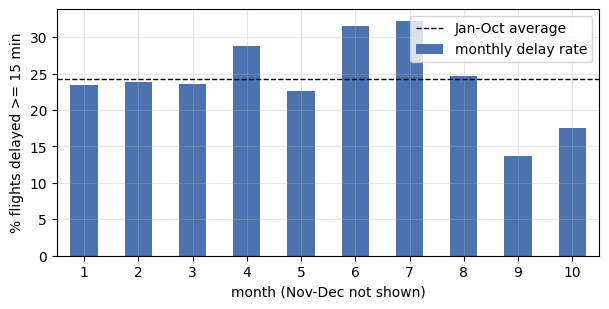

,validate month,train rows,validation rows,validation delay rate
0,6,"133,603","27,075",31.5%
1,7,"160,678","28,293",32.2%
2,8,"188,971","28,756",24.6%
3,9,"217,727","27,010",13.7%
4,10,"244,737","28,618",17.6%


In [19]:
monthly = table[table["month"] <= max(CFG.val_months)].groupby("month")["y"].agg(rows="size", delay_rate="mean")
ax = (monthly["delay_rate"] * 100).plot.bar(color="#4C72B0", rot=0, label="monthly delay rate")
ax.axhline(100 * table.loc[table["month"] <= 10, "y"].mean(), color="k", ls="--", lw=1, label="Jan-Oct average")
ax.set_ylabel("% flights delayed >= 15 min"); ax.set_xlabel("month (Nov-Dec not shown)"); ax.legend()
plt.show()

folds = rolling_origin_folds(months_all, CFG.fold_val_months)
pd.DataFrame([{"validate month": m, "train rows": f"{int(tr.sum()):,}", "validation rows": f"{int(va.sum()):,}",
               "validation delay rate": f"{y_all[va].mean():.1%}"} for m, (tr, va) in zip(CFG.fold_val_months, folds)])

**Verdict 3 — adopted.**
Monthly delay rates run from **13.7% (Sep) to 32.2% (Jul)**, so training (26.4%) and validation (15.7%) describe different worlds. That is why a threshold tuned on one split did not transfer in Phase 1, and why every later decision here uses five rolling-origin folds and day-block intervals instead of one split and one number. Decision 6 shows the same drift in the predicted probabilities.

## Decision 4 · Which features does the network get?

| | |
|---|---|
| **Rule** | **Core groups** stay because of a mechanism or the brief: hour, weekday, carrier, origin, destination, distance, congestion. **Extra groups** are admitted **only if** adding them lifts average precision (AP) with a 95% interval entirely above zero. |
| **Why the asymmetry** | The brief requires airline, origin and destination embeddings, so those stay even if the ruler cannot see their value. An extra without evidence is a column to overfit on. |
| **Evidence** | Rolling-origin out-of-fold predictions (Jun–Oct) from a gradient-boosting **ruler**, and a paired day-block bootstrap of each difference in AP against the core set. |
| **Time of day (special case)** | Phase 1 encoded departure time to the hour, plus a raw minute-of-hour. We test a finer encoding as a **swap** for `hour`. A swap is judged by the same rule as an extra, and when two encodings carry the same information and cannot be separated, the one with fewer columns wins. |
| **Caveat** | The ruler is not the network. This is screening; the DL ablation grid re-tests the admitted extras with the real model. |

In [20]:
# Every candidate group, why it exists, and whether it is core (kept by mechanism) or an extra (must earn its place).
pd.DataFrame([(g, "core" if g in CORE_GROUPS else "extra", ", ".join(cols), GROUP_WHY[g])
              for g, cols in {**CORE_GROUPS, **EXTRA_GROUPS}.items()],
             columns=["group", "kind", "columns", "why it exists"])

,group,kind,columns,why it exists
0,hour,core,"hour_sin, hour_cos",delays build up through the day; sin/cos makes...
1,weekday,core,"weekday_sin, weekday_cos",weekly travel pattern; cyclic like hour
2,carrier,core,carrier,airlines differ in operations; the brief asks ...
3,origin,core,origin,airport-specific conditions; the brief asks fo...
4,destination,core,dest,route effects; the brief asks for a destinatio...
5,distance,core,distance,route length: more exposure to en-route weathe...
6,congestion,core,scheduled_origin_hour_count,scheduled departures from the same airport in ...
7,arrival_hour,extra,"arr_hour_sin, arr_hour_cos",does arrival-time pressure add anything beyond...
8,season,extra,"year_day_sin, year_day_cos",smooth day-of-year curve; risky because the te...
9,minute_of_hour,extra,"sched_minute, sched_arr_minute",Phase 1's sched_minute / sched_arr_minute (min...


In [21]:
# Jan-Oct only: Nov-Dec never enter a decision.
dev = months_all <= max(CFG.fold_val_months)
X_dev, y_dev, months_dev, days_dev = X_all[dev], y_all[dev], months_all[dev], days_all[dev]

variants = {"core": core_columns}
for name, cols in CORE_GROUPS.items():
    variants[f"- {name}"] = [c for c in core_columns if c not in cols]          # leave one core group out
for name, cols in EXTRA_GROUPS.items():
    variants[f"+ {name}"] = core_columns + cols                                  # add one extra group
variants["~ hour -> fine_time"] = [c for c in core_columns if c not in CORE_GROUPS["hour"]] + EXTRA_GROUPS["fine_time"]   # swap

oof = {}
for name, cols in variants.items():
    t0 = time.time()
    oof[name] = out_of_fold(X_dev, y_dev, months_dev, cols, CATEGORICAL_COLUMNS, CFG.fold_val_months, CFG.seed)
    print(f"{name:<20s} {time.time() - t0:4.1f}s")

core                  5.2s
- hour                5.2s
- weekday             4.0s
- carrier             3.6s
- origin              3.6s
- destination         3.5s
- distance            3.6s
- congestion          3.5s
+ arrival_hour        4.0s
+ season              3.9s
+ minute_of_hour      3.9s
+ fine_time           3.6s
+ route               3.7s
+ flight_id           3.3s
+ past_delay          3.7s
~ hour -> fine_time   3.7s


In [22]:
point, draws = day_bootstrap(y_dev, oof, days_dev, CFG.n_bootstrap, CFG.seed)
result = compare_to_baseline(point, draws, baseline="core")
result["kind"] = np.select([result["variant"].str.startswith("+"), result["variant"].str.startswith("-"),
                            result["variant"].str.startswith("~")], ["addition", "removal", "swap"], default="baseline")
result["group"] = result["variant"].str[2:]
result["verdict"] = [apply_rule("addition" if k == "swap" else k, lo, hi) if k != "baseline" else "reference"
                     for k, lo, hi in zip(result["kind"], result["ci_low"], result["ci_high"])]
result[["variant", "AP", "delta_AP", "ci_low", "ci_high", "verdict"]].round(4)

,variant,AP,delta_AP,ci_low,ci_high,verdict
0,core,0.3739,0.0000,0.0000,0.0000,reference
1,- hour,0.3151,-0.0588,-0.0692,-0.0488,KEEP (removing it hurts)
2,- weekday,0.3710,-0.0028,-0.0129,0.0092,KEEP by mechanism (effect not measurable here)
3,- carrier,0.3647,-0.0092,-0.0109,-0.0069,KEEP (removing it hurts)
4,- origin,0.3714,-0.0025,-0.0041,-0.0009,KEEP (removing it hurts)
5,- destination,0.3747,0.0008,-0.0008,0.0024,KEEP by mechanism (effect not measurable here)
6,- distance,0.3727,-0.0012,-0.0023,-0.0001,KEEP (removing it hurts)
7,- congestion,0.3660,-0.0078,-0.0121,-0.0039,KEEP (removing it hurts)
8,+ arrival_hour,0.3743,0.0005,-0.0004,0.0013,REJECT (no measurable gain)
9,+ season,0.3840,0.0102,-0.0249,0.0481,REJECT (no measurable gain)


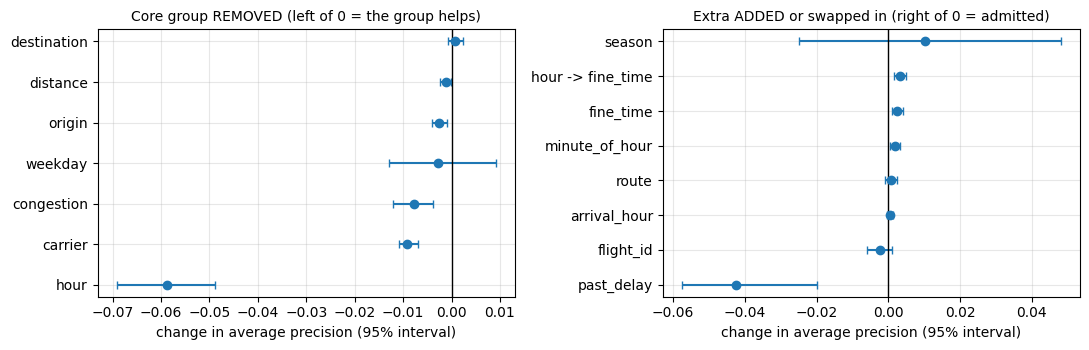

Extras that pass the admission rule: ['minute_of_hour', 'fine_time']


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, kinds, title in [(axes[0], ["removal"], "Core group REMOVED (left of 0 = the group helps)"),
                         (axes[1], ["addition", "swap"], "Extra ADDED or swapped in (right of 0 = admitted)")]:
    r = result[result["kind"].isin(kinds)].sort_values("delta_AP")
    ax.errorbar(r["delta_AP"], range(len(r)), xerr=[r["delta_AP"] - r["ci_low"], r["ci_high"] - r["delta_AP"]],
                fmt="o", capsize=3)
    ax.set_yticks(range(len(r))); ax.set_yticklabels(r["group"]); ax.axvline(0, color="k", lw=1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("change in average precision (95% interval)")
plt.tight_layout(); plt.show()

admitted = [g for g, k, v in zip(result["group"], result["kind"], result["verdict"]) if k == "addition" and v.startswith("ADMIT")]
print("Extras that pass the admission rule:", admitted or "none")

In [24]:
# Time of day is ONE piece of information with several encodings: hour only (core), hour + raw minute (Phase 1),
# and minute-resolution sin/cos (the swap). If the swap wins, keep it and drop the cruder encodings.
swap_wins = result.loc[result["kind"] == "swap", "verdict"].iloc[0].startswith("ADMIT")
tie = draws["~ hour -> fine_time"] - draws["+ minute_of_hour"]
lo, hi = np.percentile(tie, [2.5, 97.5])
print(f"swap vs 'hour + raw minute-of-hour': {point['~ hour -> fine_time'] - point['+ minute_of_hour']:+.4f} AP, 95% interval [{lo:+.4f}, {hi:+.4f}]",
      "-> cannot be separated, so the encoding with fewer columns wins" if lo < 0 < hi else "-> separable")

time_encodings = {"fine_time", "minute_of_hour"}
if swap_wins:
    recommended = [g for g in CORE_GROUPS if g != "hour"] + ["fine_time"] + [g for g in admitted if g not in time_encodings]
else:
    recommended = list(CORE_GROUPS) + admitted

# Confirm the final recommended set against the core set, on the same folds and the same resampled days.
all_groups = {**CORE_GROUPS, **EXTRA_GROUPS}
recommended_columns = [c for g in recommended for c in all_groups[g]]
final_oof = out_of_fold(X_dev, y_dev, months_dev, recommended_columns, CATEGORICAL_COLUMNS, CFG.fold_val_months, CFG.seed)
p2, d2 = day_bootstrap(y_dev, {"core": oof["core"], "recommended": final_oof}, days_dev, CFG.n_bootstrap, CFG.seed)
display(compare_to_baseline(p2, d2, "core").round(4))
print("recommended groups:", recommended)

# Rank the recommended groups by how much each one was measured to matter (removal effect on AP).
removal_effect = {g: -d for g, d, k in zip(result["group"], result["delta_AP"], result["kind"]) if k == "removal"}
removal_effect["fine_time"] = removal_effect["hour"]      # fine time-of-day replaces hour, so it inherits its role
recommended_ranked = sorted(recommended, key=lambda g: -removal_effect.get(g, 0.0))
print("groups ranked by measured contribution:", recommended_ranked)

swap vs 'hour + raw minute-of-hour': +0.0013 AP, 95% interval [-0.0003, +0.0030] -> cannot be separated, so the encoding with fewer columns wins


,variant,AP,delta_AP,ci_low,ci_high
0,core,0.3739,0.0000,0.0000,0.0000
1,recommended,0.3770,0.0032,0.0016,0.0048


recommended groups: ['weekday', 'carrier', 'origin', 'destination', 'distance', 'congestion', 'fine_time']
groups ranked by measured contribution: ['fine_time', 'carrier', 'congestion', 'weekday', 'origin', 'distance', 'destination']


**Verdict 4 — recommended groups: weekday, carrier, origin, destination, distance, congestion and time of day at minute resolution.**

| What the evidence says | Numbers (change in AP against core, 95% interval) |
|---|---|
| **Departure time is the signal** | removing it costs −0.059 (−0.069 to −0.049), more than six times the next largest effect |
| Carrier and congestion matter; origin and distance are small but measurable | carrier −0.009, congestion −0.008, origin −0.002, distance −0.001 (all intervals below zero) |
| Weekday and destination are **not measurable here** | intervals straddle zero. They stay by mechanism and by the brief (a destination embedding is required); the DL ablation grid re-tests them |
| Time of day deserves more resolution | raw minute-of-hour passes the rule (+0.0019, +0.0003 to +0.0033): hourly sin/cos throws information away. Swapping hourly sin/cos for minute-resolution sin/cos gains **+0.0028 (+0.0014 to +0.0041)** with the same two columns, and cannot be separated from hour + raw minute (difference +0.0009, −0.0006 to +0.0024). Same information, fewer columns: the swap wins and `minute_of_hour` is superseded |
| Arrival hour, route, flight number: rejected | no measurable gain (every interval includes zero) |
| **Season is undecided, not disproved** | its point estimate (+0.011) is the largest of any extra, but the interval is −0.025 to +0.049, and one year of data never shows the model Nov–Dec before the test. One year cannot answer this question |
| **Past-delay rates hurt** | −0.043 (−0.057 to −0.020), although the feature is leak-safe (verified row by row below). Likely reason, untested: lagged rates act as a season label, and the link learnt in earlier months does not carry to the next |
| The recommended set against the core set | **+0.0028 (+0.0014 to +0.0041)** using 9 columns instead of Phase 1's 2,071 |

*Caveat.* The ruler is gradient boosting, not the network. Groups that were rejected or not measurable stay in the exported files, so the DL ablation grid can re-test them with the real model.

## Decision 4b · Is the past-delay rejection robust to its own settings?

| | |
|---|---|
| **Question** | Past-delay rates *hurt* with a 7-day window and a 2-day lag. Was that just an unlucky setting? |
| **Rule** | Try a small, stated grid of the block's own settings (window 3 / 7 / 14 / 28 days at lag 2, and window 7 at lag 7). **No setting is admitted here.** A setting whose interval is entirely above zero is only *flagged* for the DL ablation grid, because five tries make a lucky pass likelier. |
| **Why** | Tuning a feature's settings is legitimate if it is bounded and judged by the same evidence bar; otherwise it is a search for a favourable number. |
| **Evidence** | the same folds and the same resampled days as Decision 4 |

In [25]:
settings = {"window 3d, lag 2": (3, 2), "window 7d, lag 2": (7, 2), "window 14d, lag 2": (14, 2),
            "window 28d, lag 2": (28, 2), "window 7d, lag 7": (7, 7)}
past_oof = {"core": oof["core"]}
for label, (window, lag) in settings.items():
    cfg_w = replace(CFG, past_window_days=window, past_lag_days=lag)
    block = PastDelayBlock(cfg_w)                                    # the guard re-checks lag >= 2 days
    extra = block.transform(flights)[is_lab].reset_index(drop=True)
    extra.columns = ["origin_delay", "carrier_delay", "nyc_delay"]    # neutral names: must not clash with the default block's columns
    X_w = pd.concat([X_all, extra], axis=1)[dev]
    past_oof[label] = out_of_fold(X_w, y_dev, months_dev, core_columns + list(extra.columns),
                                  CATEGORICAL_COLUMNS, CFG.fold_val_months, CFG.seed)

p4b, d4b = day_bootstrap(y_dev, past_oof, days_dev, CFG.n_bootstrap, CFG.seed)
robust = compare_to_baseline(p4b, d4b, "core").query("variant != 'core'").copy()
robust["verdict"] = [apply_rule("addition", lo, hi) for lo, hi in zip(robust["ci_low"], robust["ci_high"])]
flagged = robust.loc[robust["verdict"].str.startswith("ADMIT"), "variant"].tolist()
print("settings flagged for the DL ablation grid:", flagged or "none: the rejection is robust to the block's own settings")
robust.round(4)

settings flagged for the DL ablation grid: none: the rejection is robust to the block's own settings


,variant,AP,delta_AP,ci_low,ci_high,verdict
1,"window 3d, lag 2",0.3554,-0.0185,-0.0399,0.0087,REJECT (no measurable gain)
2,"window 7d, lag 2",0.3314,-0.0424,-0.0576,-0.0199,REJECT (hurts)
3,"window 14d, lag 2",0.3441,-0.0297,-0.0512,-0.0060,REJECT (hurts)
4,"window 28d, lag 2",0.3768,0.0029,-0.0276,0.0384,REJECT (no measurable gain)
5,"window 7d, lag 7",0.3292,-0.0447,-0.0659,-0.0148,REJECT (hurts)


**Verdict 4b — the rejection stands.**
Three of five settings *hurt* (7-day window at lag 2: −0.043; 14-day: −0.028; 7-day at lag 7: −0.044; every interval entirely below zero) and two cannot be told from nothing (3-day: −0.021, interval −0.043 to +0.007; 28-day: +0.003, interval −0.028 to +0.039, too wide to say anything). No setting passes the rule, so none is flagged for the DL grid. A feature that fails at every sensible window is unlikely to be rescued by tuning its window. [Likely] the idea itself (the recent delay level predicts the next day's) does not carry from earlier months to the next in a single year of data.

## Decision 5 · Embeddings for categories, not PCA

| | |
|---|---|
| **Rule** | Carrier, origin and destination enter the network as **learned embeddings**. PCA is used only as a **diagnostic**, and later to plot the learned embeddings. |
| **Mechanism** | An embedding is a one-hot vector times a weight matrix whose width *d* is below the number of categories: a low-rank projection **chosen by the loss**. PCA chooses directions by variance and never sees the label. |
| **Evidence** | (a) how many components PCA needs to describe the one-hot block, (b) PCA/SVD-then-classifier against simply pruning, (c) a five-line demonstration that an embedding is a lookup in a one-hot product |
| **We change our mind if** | SVD-then-classifier beats the pruned set with an interval above zero. |

,components needed,one-hot columns
keep 50% of variance,14,2063
keep 80% of variance,236,2063
keep 90% of variance,670,2063
keep 95% of variance,1080,2063


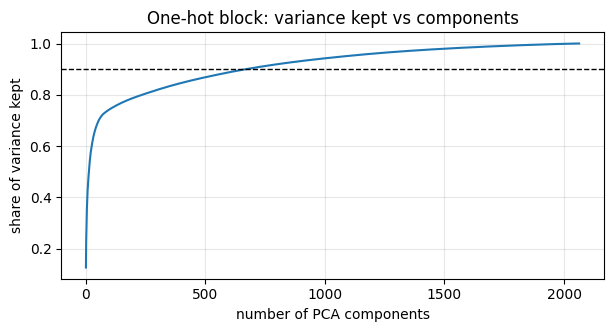

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# "Phase 1 style" input: the 12 numeric features + one-hot of carrier, origin, destination and the RAW flight number.
phase1_numeric = ["distance", "scheduled_origin_hour_count", "hour_sin", "hour_cos", "weekday_sin", "weekday_cos",
                  "arr_hour_sin", "arr_hour_cos", "year_day_sin", "year_day_cos", "sched_minute", "sched_arr_minute"]
wide_categorical = ["carrier", "origin", "dest", "flight"]
wide = X_all.assign(flight=flights.loc[is_lab, "flight"].astype(str).to_numpy())

# (a) How compressible is the one-hot block? Exact eigen-spectrum of its covariance, train rows only.
M = OneHotEncoder(handle_unknown="ignore", min_frequency=20).fit_transform(wide.loc[train_rows, wide_categorical]).astype("float64")
n = M.shape[0]
mean = np.asarray(M.mean(axis=0)).ravel()
cov = (M.T @ M).toarray() / (n - 1) - np.outer(mean, mean) * n / (n - 1)
eigenvalues = np.clip(np.linalg.eigvalsh(cov)[::-1], 0, None)
share_kept = np.cumsum(eigenvalues) / eigenvalues.sum()
needed = {f"keep {int(q * 100)}% of variance": int(np.searchsorted(share_kept, q) + 1) for q in (0.5, 0.8, 0.9, 0.95)}
display(pd.DataFrame({"components needed": needed, "one-hot columns": M.shape[1]}))

plt.plot(range(1, len(share_kept) + 1), share_kept)
plt.axhline(0.9, color="k", ls="--", lw=1); plt.xlabel("number of PCA components"); plt.ylabel("share of variance kept")
plt.title("One-hot block: variance kept vs components"); plt.show()

In [27]:
# (b) The plan "reduce first, then classify" against simply pruning. Logistic regression is the ruler here.
def make_lr(numeric, categorical, svd_components=None):
    pre = ColumnTransformer([("num", StandardScaler(), numeric),
                             ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), categorical)])
    steps = [("pre", pre)]
    if svd_components:
        steps.append(("svd", TruncatedSVD(svd_components, random_state=CFG.seed)))
    return Pipeline(steps + [("lr", LogisticRegression(max_iter=500))])

core_numeric = ["distance", "scheduled_origin_hour_count", "hour_sin", "hour_cos", "weekday_sin", "weekday_cos"]
setups = {"everything (Phase 1 style)": (phase1_numeric, wide_categorical, None),
          "everything -> SVD 100":       (phase1_numeric, wide_categorical, 100),
          "pruned core":                 (core_numeric, ["carrier", "origin", "dest"], None)}
val_pred, columns_in = {}, {}
for name, (num, cat, k) in setups.items():
    model = make_lr(num, cat, k).fit(wide.loc[train_rows, num + cat], y_all[train_rows])
    val_pred[name] = model.predict_proba(wide.loc[val_rows, num + cat])[:, 1]
    columns_in[name] = model.named_steps["pre"].transform(wide.loc[val_rows, num + cat].iloc[:5]).shape[1]

point5, draws5 = day_bootstrap(y_all[val_rows], val_pred, days_all[val_rows], CFG.n_bootstrap, CFG.seed)
vs_everything = compare_to_baseline(point5, draws5, "everything (Phase 1 style)").assign(comparison="vs everything")
vs_svd = compare_to_baseline(point5, draws5, "everything -> SVD 100").query("variant == 'pruned core'").assign(comparison="vs SVD 100")
out5 = pd.concat([vs_everything, vs_svd]).assign(input_columns=lambda d: d["variant"].map(columns_in))
out5[["comparison", "variant", "input_columns", "AP", "delta_AP", "ci_low", "ci_high"]].round(4).reset_index(drop=True)

,comparison,variant,input_columns,AP,delta_AP,ci_low,ci_high
0,vs everything,everything (Phase 1 style),2075,0.2348,0.0000,0.0000,0.0000
1,vs everything,everything -> SVD 100,2075,0.2392,0.0044,-0.0010,0.0130
2,vs everything,pruned core,121,0.2440,0.0093,0.0024,0.0183
3,vs SVD 100,pruned core,121,0.2440,0.0048,-0.0025,0.0115


In [28]:
# (c) An embedding IS a lookup: one-hot vector times a table of weights.
rng = np.random.default_rng(0)
V, d = 5, 3                                  # 5 categories, 3-dimensional embedding
table_W = rng.normal(size=(V, d))            # the embedding table
ids = np.array([2, 0, 4])
print("lookup == one-hot @ table:", np.allclose(table_W[ids], np.eye(V)[ids] @ table_W))

# What the low-rank constraint buys (illustrative hidden width H=64, embedding size capped at 8):
H = 64
sizes = {c: int(X_all.loc[train_rows, c].nunique()) for c in ["carrier", "origin", "dest", "route"]}
pd.DataFrame({c: {"categories": V_, "first-layer weights, one-hot (V x H)": V_ * H,
                  "embedding + next layer (V x d + d x H)": V_ * min(8, V_) + min(8, V_) * H}
              for c, V_ in sizes.items()}).T

lookup == one-hot @ table: True


,categories,"first-layer weights, one-hot (V x H)",embedding + next layer (V x d + d x H)
carrier,16,1024,640
origin,3,192,201
dest,102,6528,1328
route,218,13952,2256


**Verdict 5 — adopted: embeddings in the network; PCA only as a diagnostic.**

* The one-hot block needs **670 of 2,063 components** to keep 90% of its variance (1,080 for 95%). It does not compress, because about 1,950 of its columns are near-orthogonal flight-number indicators.
* "Reduce first, classify second" (SVD to 100 components) is **not measurably better than doing nothing**: +0.0045 AP (−0.0010 to +0.0131).
* Pruning is: **+0.0093** (+0.0024 to +0.0185) with 121 named columns instead of 2,075.
* Pruned versus SVD cannot be separated on validation (+0.0048, −0.0025 to +0.0115). So the case against PCA is *no measurable gain, anonymous components, and the mechanism above*, not a proven loss. The change-of-mind condition we set (SVD beats pruning with an interval above zero) is not met.
* An embedding is a lookup in a one-hot product (checked above). It cuts the first-layer weights for destination from 6,528 to 1,328 and for route from 13,952 to 2,256 (illustrative H = 64, d = 8). For origin (3 values) it saves nothing: a 3-category embedding is a re-parameterised one-hot. We keep it because the brief asks for it.

## Decision 6 · Class imbalance is not "fixed" in the features

| | |
|---|---|
| **Rule** | No resampling and no re-weighting at feature level. Imbalance is handled **at training time** as an ablation arm (none / `pos_weight` / undersampling / focal loss), and probabilities are calibrated afterwards with **temperature scaling**. |
| **Why** | The deliverable is a *calibrated probability*. Balancing changes the base rate the model sees, so its outputs stop being probabilities. About a quarter delayed is a mild imbalance, and the ranking metrics (PR-AUC, ROC-AUC) are the ones built to cope with it. |
| **Plain SMOTE is out** | It interpolates between rows; interpolating category ids invents flights that never operated. |
| **Evidence** | the same logistic regression trained three ways and scored on validation: ranking (AP, ROC-AUC) against calibration (mean predicted vs observed rate, ECE, Brier) |
| **We change our mind if** | an arm improves recall at a fixed precision **after** recalibration, with an interval above zero. That test belongs to the DL ablation grid. |

In [29]:
cat_core = ["carrier", "origin", "dest"]
cols = core_numeric + cat_core
X_tr, y_tr = wide.loc[train_rows, cols], y_all[train_rows]
X_va, y_va = wide.loc[val_rows, cols], y_all[val_rows]

def arm(X_fit, y_fit, **params):
    return make_lr(core_numeric, cat_core).set_params(**params).fit(X_fit, y_fit).predict_proba(X_va)[:, 1]

rng = np.random.default_rng(CFG.seed)
pos, neg = np.where(y_tr == 1)[0], np.where(y_tr == 0)[0]
balanced_rows = np.concatenate([pos, rng.choice(neg, size=len(pos), replace=False)])

arms = {"none": arm(X_tr, y_tr),
        "class_weight = balanced": arm(X_tr, y_tr, lr__class_weight="balanced"),
        "undersample to 50/50": arm(X_tr.iloc[balanced_rows], y_tr[balanced_rows])}
imbalance = pd.DataFrame({name: calibration_summary(y_va, p) for name, p in arms.items()}).T
imbalance.round(3)

,AP,ROC_AUC,mean_predicted,observed_rate,Brier,ECE
none,0.244,0.652,0.264,0.157,0.141,0.107
class_weight = balanced,0.243,0.652,0.479,0.157,0.237,0.322
undersample to 50/50,0.243,0.652,0.480,0.157,0.238,0.323


**Verdict 6 — adopted: no balancing in the features.**

* **Ranking does not move:** AP 0.244 / 0.243 / 0.243 and ROC-AUC 0.652 in all three arms.
* **Calibration does:** mean predicted probability jumps from 0.264 to 0.48 (observed 0.157), ECE from 0.107 to 0.322, Brier from 0.141 to 0.237. Class weighting and 50/50 undersampling behave the same way, as theory predicts: both shift the logit by about log(negatives / positives).
* **The plain model is already off** on validation (0.264 predicted, 0.157 observed, ECE 0.107). That is prevalence drift (26.4% → 15.7%), not class imbalance. One temperature stretches logits and cannot remove a base-rate shift, so the calibration step in the DL notebooks must compare *temperature only* with *temperature + bias* on the most recent fold. This refines the earlier plan on the strength of this evidence.

## Decision 7 · How the network sees the data

| | |
|---|---|
| **Rule** | Categories → integer ids built **from train only**; categories with fewer than 100 train flights (and anything unseen later) share index 0 = `<UNK>`. Numbers → z-scores with the **train** mean and std. |
| **Why** | Statistics fitted on validation or test would leak their distribution. A reserved `<UNK>` lets the network meet a new airport or flight number at inference time instead of crashing. Very rare categories get noisy embeddings, so sharing one token acts as a regulariser. |
| **Evidence** | vocabulary size and the share of **validation** rows that fall into `<UNK>`, for three thresholds |

In [30]:
final_categorical = sorted(CATEGORICAL_COLUMNS)
final_numeric = [c for cols in {**CORE_GROUPS, **EXTRA_GROUPS}.values() for c in cols if c not in CATEGORICAL_COLUMNS]

rows = []
for m in (20, 100, 500):
    enc = DLEncoder(final_categorical, final_numeric, m).fit(parts["train"])
    cover = enc.coverage(parts["val"])
    rows.append({"min_count": m, **{f"{c}: vocab / rows in <UNK>": f"{len(enc.vocab_[c])} / {cover[c]:.1%}" for c in final_categorical}})
pd.DataFrame(rows).set_index("min_count")

,carrier: vocab / rows in <UNK>,dest: vocab / rows in <UNK>,flight_top: vocab / rows in <UNK>,origin: vocab / rows in <UNK>,route: vocab / rows in <UNK>
min_count,,,,,
20,16 / 0.0%,96 / 0.1%,252 / 0.0%,4 / 0.0%,200 / 0.7%
100,16 / 0.0%,91 / 0.2%,252 / 0.0%,4 / 0.0%,183 / 1.5%
500,12 / 0.7%,63 / 4.0%,9 / 16.8%,4 / 0.0%,115 / 10.3%


**Verdict 7 — minimum count 100.**
At 100, every column keeps at least **98.5%** of validation rows in a real category (worst case: route, 1.5% in `<UNK>`). A threshold of 500 would send 10.3% of rows (route), 16.9% (flight number) and 4.0% (destination) to `<UNK>`. A threshold of 20 buys back under one point of coverage (route 1.5% → 0.7%) for 17 more route tokens. Rule: the smallest vocabulary that keeps validation coverage above 98%.

## Decision 8 · The featured dataset is saved once, and every later notebook reads it

| | |
|---|---|
| **Rule** | Features are built **once**, here, and saved. The baseline, network and rescheduling notebooks read the saved files through `DatasetStore`; they never recompute features. |
| **Why** | (1) Every model sees identical rows and identical splits, which is what the brief's "fair comparison" needs. (2) Two teammates cannot build the features slightly differently. (3) A new Colab session starts from files, not from a five-minute rebuild. (4) The encoder (vocabularies, train means and stds) is saved as data, so the what-if analysis can encode a modified schedule exactly as training did. |
| **Format** | gzip-compressed CSV: readable anywhere, no extra library, about a quarter of the size. |
| **Evidence** | the round-trip tests below: counts, the join back to the raw file, and an encoder rebuilt from `feature_spec.json` reproducing the saved values |

| File in `Datasets/processed/` | Content | Used by |
|---|---|---|
| `dl_train.csv.gz`, `dl_val.csv.gz`, `dl_test.csv.gz` | model-ready: category ids (`*_idx`) and z-scored numbers for **every candidate group**, plus `row_id`, `y`, `month`, `date` | the DL notebooks (they pick groups through the spec) |
| `features_all.csv.gz` | the same flights as readable engineered features (text categories, unscaled numbers) with a `split` label | analysis, error inspection, the what-if |
| `feature_spec.json` | vocabularies, train means/stds, group → columns, recommended groups (and their ranking), split months, label definition, file manifest | every notebook; also rebuilds the encoder |

In [31]:
encoder = DLEncoder(final_categorical, final_numeric, CFG.min_category_count).fit(parts["train"])   # TRAIN rows only
meta_columns = ["row_id", "y", "month", "date"]
model_ready = {name: pd.concat([encoder.transform(part), part[meta_columns]], axis=1) for name, part in parts.items()}

all_groups = {**CORE_GROUPS, **EXTRA_GROUPS}
readable_columns = ["row_id", "split", "month", "date", "y"] + [c for cols in all_groups.values() for c in cols]
readable = table.assign(split=ChronologicalSplit(CFG).assign(table))[readable_columns]

def encoded_name(col):
    return f"{col}_idx" if col in CATEGORICAL_COLUMNS else col

store = DatasetStore(ROOT / CFG.out_dir)
files = store.save(readable, model_ready, encoder, extra={
    "groups": {g: [encoded_name(c) for c in cols] for g, cols in all_groups.items()},
    "core_groups": list(CORE_GROUPS),
    "recommended_groups": recommended,
    "recommended_groups_ranked": recommended_ranked,
    "not_recommended_extras": [g for g in EXTRA_GROUPS if g not in recommended],
    "target": "y", "meta_columns": meta_columns,
    "label_definition": f"arr_delay >= {CFG.delay_minutes} minutes",
    "prediction_time": CFG.prediction_time,
    "splits": {"train": CFG.train_months, "val": CFG.val_months, "test": CFG.test_months},
    "rolling_origin_validation_months": CFG.fold_val_months,
})
pd.DataFrame(files).T[["rows", "size_mb"]]

,rows,size_mb
dl_train.csv.gz,217727,5.5
dl_val.csv.gz,55628,1.4
dl_test.csv.gz,53991,1.4
features_all.csv.gz,327346,7.2


### Round-trip tests
The next notebooks trust these files. Each assumption is checked, not remembered. The files are opened exactly the way a model notebook will open them.

In [32]:
store = DatasetStore(ROOT / CFG.out_dir)
spec = store.spec()
saved = {n: pd.read_csv(store.folder / f"dl_{n}.csv.gz", parse_dates=["date"]) for n in ("train", "val", "test")}
readable_saved = store.load_readable()
forbidden = {c for c, (status, _) in COLUMN_POLICY.items() if status in FORBIDDEN_STATUSES}

def check(label, ok):
    assert ok, f"FAILED: {label}"
    print(f"passed | {label}")

check("no post-departure / target / unreliable column was saved, in any file",
      forbidden.isdisjoint(saved["train"].columns) and forbidden.isdisjoint(readable_saved.columns))
check("train ends before val starts, val ends before test starts",
      saved["train"]["date"].max() < saved["val"]["date"].min() < saved["val"]["date"].max() < saved["test"]["date"].min())
check("every labelled flight landed in exactly one split",
      sum(len(s) for s in saved.values()) == int(is_lab.sum()) == len(readable_saved))
check("row_id is unique and joins back to the raw file",
      readable_saved["row_id"].is_unique and readable_saved["row_id"].isin(flights["id"]).all())
check("model-ready and readable files hold the same flights in the same order",
      all(saved[n]["row_id"].tolist() == readable_saved.loc[readable_saved["split"] == n, "row_id"].tolist() for n in saved))
check("no missing values anywhere", all(not s.isna().any().any() for s in [*saved.values(), readable_saved]))
check("category ids stay inside each vocabulary",
      all(saved[n][f"{c}_idx"].between(0, spec["categorical"][c]["vocab_size"] - 1).all()
          for n in saved for c in final_categorical))
check("numbers are standardised with TRAIN statistics (train mean ~ 0, test is not re-centred)",
      saved["train"][final_numeric].mean().abs().max() < 1e-4 and saved["test"][final_numeric].mean().abs().max() > 1e-3)

# An encoder rebuilt from the saved spec must reproduce the saved values: this is what the what-if analysis relies on.
rebuilt = store.load_encoder()
sample = readable_saved[readable_saved["split"] == "val"].head(2000)
again, saved_val = rebuilt.transform(sample), saved["val"].head(2000)
check("an encoder rebuilt from feature_spec.json reproduces the saved values",
      all((again[f"{c}_idx"].to_numpy() == saved_val[f"{c}_idx"].to_numpy()).all() for c in final_categorical)
      and np.allclose(again[final_numeric].to_numpy(), saved_val[final_numeric].to_numpy(), atol=1e-5))

# Leak check on the one feature that touches outcomes: recompute 3 rows by brute force.
rng = np.random.default_rng(1)
for i in rng.choice(flights[flights["labelled"]].index.to_numpy(), 3, replace=False):
    row, day = flights.loc[i], flights.loc[i, "date"]
    hist = lab[(lab["date"] >= day - pd.Timedelta(days=8)) & (lab["date"] <= day - pd.Timedelta(days=2)) & (lab["origin"] == row["origin"])]
    manual = (hist["y"].sum() + CFG.past_strength * CFG.past_prior) / (len(hist) + CFG.past_strength)
    check(f"past-delay feature of row {i} equals a brute-force rate over days <= D-2 (latest day used: {hist['date'].max().date()}, flight day: {day.date()})",
          abs(features.loc[i, f"origin_delay_{CFG.past_window_days}d"] - manual) < 1e-9 and hist["date"].max() <= day - pd.Timedelta(days=2))
print("\nrecommended groups for the network:", spec["recommended_groups"])

passed | no post-departure / target / unreliable column was saved, in any file
passed | train ends before val starts, val ends before test starts
passed | every labelled flight landed in exactly one split
passed | row_id is unique and joins back to the raw file
passed | model-ready and readable files hold the same flights in the same order
passed | no missing values anywhere
passed | category ids stay inside each vocabulary
passed | numbers are standardised with TRAIN statistics (train mean ~ 0, test is not re-centred)
passed | an encoder rebuilt from feature_spec.json reproduces the saved values
passed | past-delay feature of row 173278 equals a brute-force rate over days <= D-2 (latest day used: 2013-07-06, flight day: 2013-07-08)
passed | past-delay feature of row 159807 equals a brute-force rate over days <= D-2 (latest day used: 2013-06-22, flight day: 2013-06-24)
passed | past-delay feature of row 254957 equals a brute-force rate over days <= D-2 (latest day used: 2013-10-01, fli

### What the next notebook does with these files
Five lines: open the store, load the recommended groups, read the vocabulary sizes for the embedding layers. No feature code is re-run.

In [33]:
store = DatasetStore(ROOT / CFG.out_dir)
X_train, y_train, meta_train = store.load_split("train")        # the recommended groups, in a fixed column order
X_dev, y_dev_saved, meta_dev = store.load_development()         # train + val (Jan-Oct): rolling-origin folds. Test is never included
vocab = {c: v["vocab_size"] for c, v in store.spec()["categorical"].items() if f"{c}_idx" in X_train.columns}
print("train inputs:", X_train.shape, "| development inputs:", X_dev.shape, "| test rows are untouched until the final evaluation")
print("embedding vocabulary sizes:", vocab)
X_train.head(3)

train inputs: (217727, 9) | development inputs: (273355, 9) | test rows are untouched until the final evaluation
embedding vocabulary sizes: {'carrier': 16, 'dest': 91, 'origin': 4}


,weekday_sin,weekday_cos,carrier_idx,origin_idx,dest_idx,distance,scheduled_origin_hour_count,tod_sin,tod_cos
0,1.06415,0.874318,1,1,16,0.482310,-3.10177,1.51392,1.068230
1,1.06415,0.874318,1,3,16,0.504062,-3.26947,1.52724,0.952391
2,1.06415,0.874318,5,2,9,0.059500,-2.93407,1.53429,0.860674


**Verdict 8 — adopted.**
Four files in `Datasets/processed/` now carry everything a later notebook needs: **217,727** train, **55,628** validation and **53,991** test rows (327,346 flights in all), the same flights as a readable table, and a spec that rebuilds the encoder. All round-trip tests pass: nothing forbidden was saved, ids join back to the raw file, and an encoder rebuilt from the spec reproduces the saved values, so a modified schedule can later be encoded exactly as training was. Notebook 04 starts from these files and nothing else.

## Decision register

| # | Decision | Support | Key evidence | Re-tested later with the real network? |
|---|---|---|---|---|
| 1 | Predict at 18:00 the day before; forbid post-departure fields | mechanism + evidence | the leak lifts ROC-AUC 0.670 → 0.901; the guard refuses both mistakes | no |
| 2 | Congestion counted on the full schedule | mechanism + evidence | 27.7 / 14.7 / 22.5% of rows differ; reproduces Phase 1's audit numbers | no |
| 3 | Month split, saved once; rolling-origin folds; day-block bootstrap | mechanism + evidence | monthly delay rate 13.7% to 32.2% | no |
| 4 | Inputs: weekday, carrier, origin, destination, distance, congestion, minute-resolution time of day | evidence + parsimony + the brief | +0.0028 AP against core (+0.0014 to +0.0041); 9 columns instead of 2,071 | yes: season, past delay, weekday, destination |
| 4b | Past-delay stays out, whatever its settings | evidence | five settings tried (Decision 4b) | only if a setting was flagged |
| 5 | Embeddings, not PCA | mechanism + evidence + parsimony | 670 of 2,063 components for 90%; SVD +0.0045 (interval spans 0) | yes: embedding-size sweep |
| 6 | No balancing in features; calibrate afterwards | mechanism + evidence | ECE 0.107 → 0.322 with AP flat; drift is the bigger problem | yes: imbalance arms; temperature vs temperature + bias |
| 7 | Train-only vocabulary and z-scores, min count 100, `<UNK>` | mechanism + evidence | at least 98.5% coverage at 100 | no |
| 8 | Featured dataset saved once; later notebooks only read it | mechanism + evidence | round-trip tests pass; encoder rebuilds from the spec | no |

**Deliberately not decided here:** architecture, embedding sizes, loss, activation, initialisation, optimiser, early-stopping metric, calibration method.